# 07 Fig 2: the event field and the slip model

```
Created on Mon Sep 28 2026
@author: daniellelindsay
Run in opera_disp_feb13, after 06 and 07. Seconds.
```

**What this notebook does.** Draws Fig 2 from the products of notebook 06
(the maps and profiles, `fig2_inputs.npz`) and notebook 07 (the model row,
`fig2_model_row.npz`). It computes no numbers and registers nothing: every
number on the figure was registered where it was made.

Moved out of `06_event_field_geometry` on 2026-09-28 so the model row is the
real model. Fig 2 is the fault-parallel and vertical version (Dani,
2026-09-28); the per-track LOS version is the supplement figure.

**Inputs**: `06_event_field_geometry/fig2_inputs.npz`,
`07b_uniform_model_tests/fig2_model_row.npz` (placeholders if absent),
`hayward_fault_profiles.csv`, the alignment-array summary.

**Figures**: `fig2_fault_parallel_vertical_coh<c>_<n>ev` (Fig 2) and
`figS_los_maps_profiles_coh<c>_<n>ev` (the LOS version, supplement).

In [1]:
import os

import insar_utils as utils
from TulePond_filepaths import (common_paths, creepmeters, paths_out, dist_min, dist_max,
                                fig2_map_centre_km, fig2_map_half_km, fig2_map_extra_km, profile_smooth_km)

import numpy as np
import pandas as pd
import pyproj
import xarray as xr
from scipy.spatial import cKDTree
import pygmt

## Constants

In [2]:
notebook = "07c_fig2"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)

# the running median drawn on the profiles
median_bin_m = 150.0            # running-median bin (five pixels), taken on each side of the fault separately
median_col, grey, ann_col = "black", "gray55", "black"         # per-side running median (black); pixels; block annotation
homog_col, hetero_col = "#0072B2", "#D55E00"                   # homogeneous model blue; heterogeneous (aligned SFCVM) model vermillion
model_col = homog_col          # reset below from the model product: vermillion when it is the PyLith aligned-SFCVM model
xfault_step_m = (dist_min * 1e3, dist_max * 1e3)   # the near-fault band the block amplitudes use (m), for the caption

# Fig 2 map window (unrotated, north up): centred on the trace at map_centre_km from Point Pinole,
# +/- map_half_km east-west, +/- (map_half_km + map_extra_km) north-south, as the draft (10.4 x 12 km).
# The values live in TulePond_filepaths so Fig 1 (notebook 04) draws the same box.
map_centre_km, map_half_km, map_extra_km = fig2_map_centre_km, fig2_map_half_km, fig2_map_extra_km
aa_labelled = ["HGIL", "HRKT"]  # the arrays named in the paper (notebook 08); the other arrays of the section are not drawn
aa_label_pos = {"HGIL": ("RB", "-0.12c/0.08c"),   # HGIL up-left: the west well 29A006 is labelled at its own height below it
                "HRKT": ("LM", "0.15c/0.12c")}   # (justify, offset) of each label about its symbol

f_fig2_in = os.path.join(paths_out["06_event_field_geometry"], "fig2_inputs.npz")
aa_file = common_paths["aa_summary"]

## Load: the maps and profiles from notebook 06, the trace

The per-track maps and profiles were made in 06; here they are only unpacked
into the same names 06 used, so the drawing code reads the same.

In [3]:
z = np.load(f_fig2_in)
print(str(z["provenance"]))
lon_g, lat_g, Xg, Yg = z["lon"], z["lat"], z["X"], z["Y"]
nr, nc = lon_g.shape
strike, coh_maps, cross_m = float(z["strike"]), float(z["coh_maps"]), float(z["cross_m"])
names = [str(n_) for n_ in z["names"]]
tracks = ["ascending", "descending"]
event_maps = {o: dict(rate=z[f"rate_{o}"]) for o in tracks}
mean_event = {o: dict(mean=z[f"event_{o}"], n=int(z["n_events"])) for o in tracks}
fp_rate, fp_evt = z["fp_rate"], z["fp_event"]
up_rate, up_evt = z["up_rate"], z["up_event"]


def unpack(field):
    """The profiles of one field (fp, ascending, descending) as 06 held them."""
    out = {}
    for n_ in names:
        p = {k: z[f"prof_{field}_{n_}_{k}"] for k in ("d", "v", "de", "ve", "ends")}
        p["blocks"] = {blk: dict(amp=float(z[f"prof_{field}_{n_}_{blk}_amp"]), se=float(z[f"prof_{field}_{n_}_{blk}_se"]))
                       for blk in ("W", "E")}
        out[n_] = p
    return out


profiles = unpack("fp")
up_profiles = unpack("up")
los_profiles = {o: unpack(o) for o in tracks}

# the grid: pixel centres on a regular UTM lattice (asserted), so a pixel is found by its index
epsg = int(z["epsg"])
to_utm = pyproj.Transformer.from_crs(4326, epsg, always_xy=True)
to_ll = pyproj.Transformer.from_crs(epsg, 4326, always_xy=True)
dx, dy = float(Xg[0, 1] - Xg[0, 0]), float(Yg[1, 0] - Yg[0, 0])
assert np.allclose(np.diff(Xg, axis=1), dx) and np.allclose(np.diff(Yg, axis=0), dy), "the 06 grid is not regular"
x_origin, y_origin = float(Xg[0, 0]) - 0.5 * dx, float(Yg[0, 0]) - 0.5 * dy     # outer corner of the first pixel

# the trace, and the unit normal pointing to the east (NE) block, as in 06
prof = pd.read_csv(common_paths["fault_profiles"])
fx, fy = to_utm.transform(prof.ft_lon.values, prof.ft_lat.values)
tree = cKDTree(np.c_[fx, fy])
nrm = np.array([np.sin(np.deg2rad(strike - 90)), np.cos(np.deg2rad(strike - 90))])


def running_median(d, v, bin_m=median_bin_m):
    """Binned median on each side of the fault separately: the bin edges start at
    the trace and run outward, so no bin (and no drawn segment) straddles the
    fault. Returns a list of (x, median) arrays, one per side (west, east)."""
    out = []
    for sgn in (-1, 1):
        edges = np.sort(sgn * np.arange(0.0, cross_m + bin_m, bin_m))
        idx = np.digitize(d, edges)
        xc, med = [], []
        for i in range(1, len(edges)):
            m_ = (idx == i) & (sgn * d > 0)
            if m_.sum() >= 3:
                xc.append(0.5 * (edges[i - 1] + edges[i])); med.append(np.median(v[m_]))
        out.append((np.array(xc), np.array(med)))
    return out

06_event_field_geometry | git 5952336+ | 2026-09-30 22:00


## Fig S: the observations on each track, and the model row (notebook 07)

Layout (Dani's sketch, 2026-09-23). Row 1, the inter-event rate: the
ascending and descending LOS maps sharing one colour bar, then the X-X' and
Y-Y' profiles of each track (pixels in grey, a per-side running median in
blue). Row 2, the mean event: the same, with each block's near-fault amplitude
over its own far field (text at the panel bottom). Row 3 is the
model, descending only, which notebook 07 will draw (the quadtree samples,
the model, the residual, and slip with depth); until then it is three
labelled empty frames of the sizes 07 will fill, so the page can be judged.
The maps are LOS, positive toward the satellite, so the same right-lateral
step is blue-over-red on ascending and red-over-blue on descending. The
fault-parallel maps and profiles this figure used to show are now a
supplementary figure (next section).

map window: 10.4 x 12 km about 59.5 km (37.5547 N)
alignment arrays in the window: HAPP, HCAM, HGIL, HHAN, HONO, HPIN, HPMD, HRKT, HSGR, HUNI
map panels 3.50 x 3.95 cm; figure ~17.3 x 15.3 cm
wells: 4S/1W-27D008 (east) 37.56329 -121.96783, 4S/1W-29A006 (west) 37.56275 -121.98814 | rain gauges: Fremont 37.5422 -122.0158, Newark 37.5147 -122.0325
Fig 2 model row from /Users/dlindsay/work/proj_TulePond_DISP/outputs/08a_3d_model/fig2_model_row_pylith_nuggetcd.npz (tag '_pylith_nuggetcd')


K line: 539 crossings, Gaussian sigma 0.15 km
common pixel mask for the four maps: 149115 pixels (27% of the box)


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-02/figS_los_maps_profiles_coh0.9_5ev.png


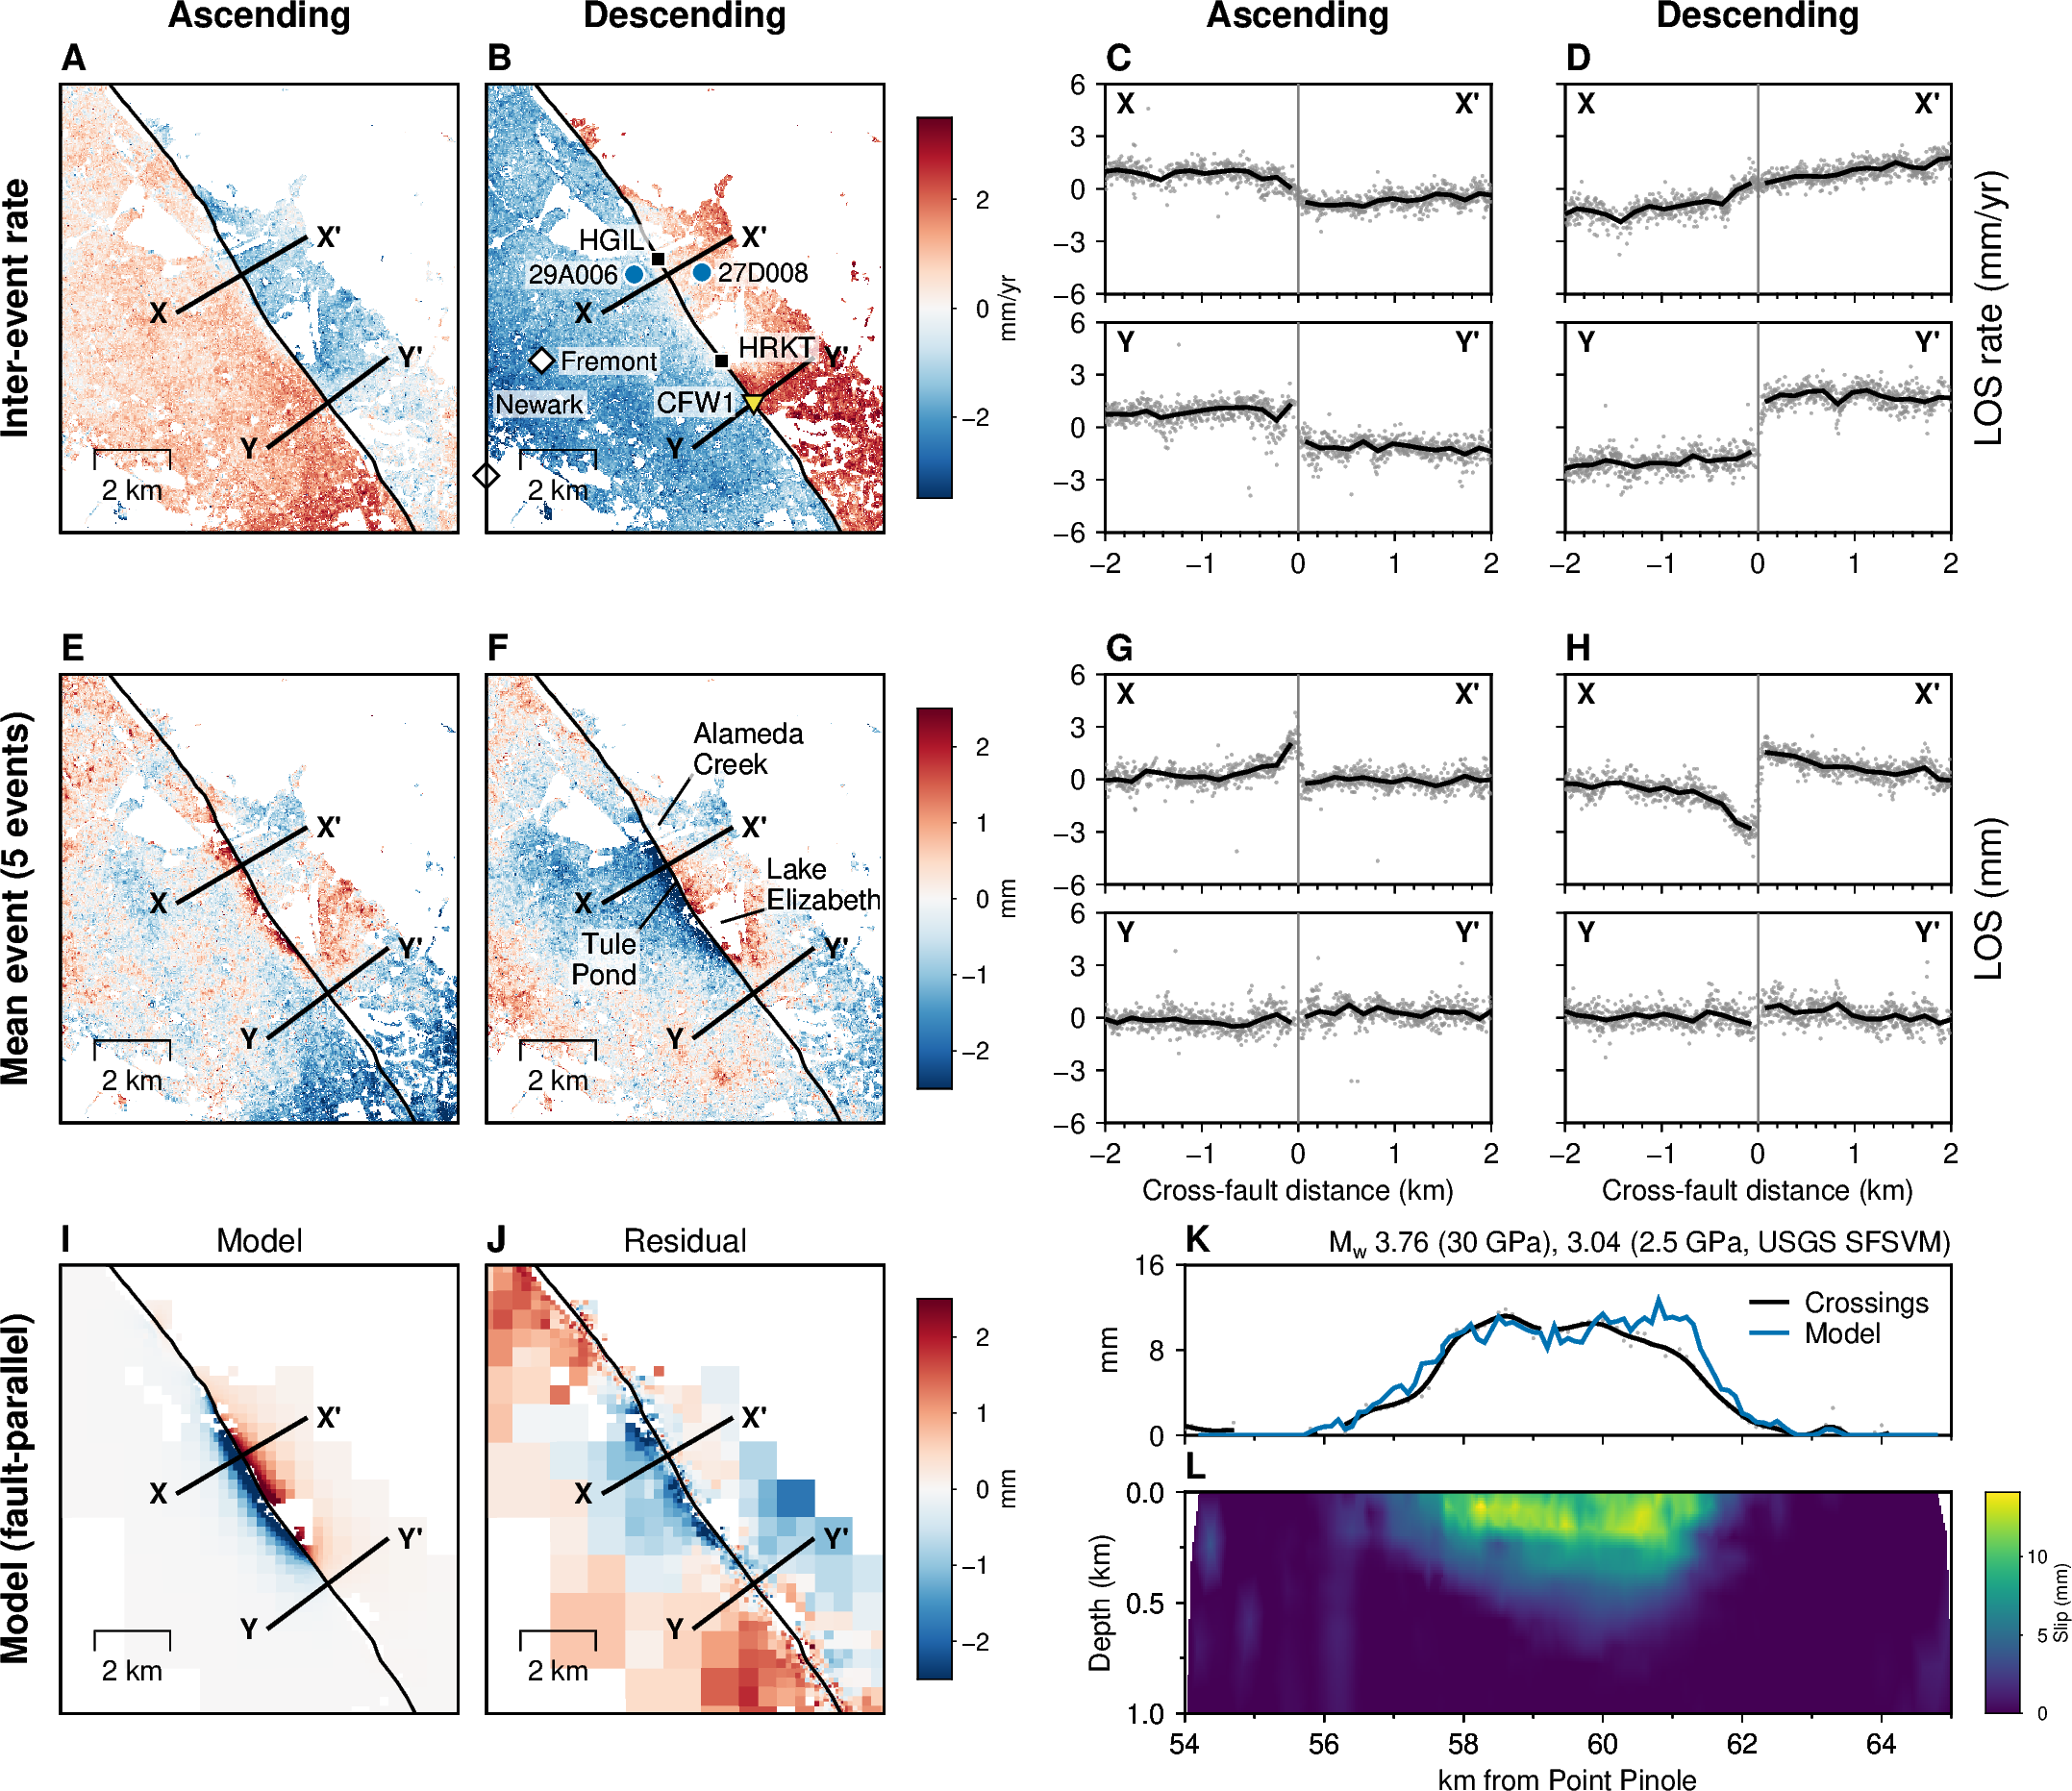

In [4]:
# --- the map window: a lon/lat box about the trace point map_centre_km from Point Pinole
km_of = utils.lat_to_km_map(common_paths["fault_profiles"])
j_c = int(np.argmin(np.abs(km_of(prof.ft_lat.values) - map_centre_km)))
xc, yc = (float(t_) for t_ in to_utm.transform(prof.ft_lon[j_c], prof.ft_lat[j_c]))
lon_w, lat_s = to_ll.transform(xc - map_half_km * 1e3, yc - (map_half_km + map_extra_km) * 1e3)
lon_e, lat_n = to_ll.transform(xc + map_half_km * 1e3, yc + (map_half_km + map_extra_km) * 1e3)
region_map = [lon_w, lon_e, lat_s, lat_n]
print(f"map window: {2 * map_half_km:g} x {2 * (map_half_km + map_extra_km):g} km about {map_centre_km:g} km ({prof.ft_lat[j_c]:.4f} N)")

# the maps on a regular lon/lat grid (nearest 30 m pixel)
lat_q = np.arange(lat_s - 0.002, lat_n + 0.002, 0.00025)
lon_q = np.arange(lon_w - 0.002, lon_e + 0.002, 0.0003)
LONq, LATq = np.meshgrid(lon_q, lat_q)
Eq, Nq = to_utm.transform(LONq, LATq)
ci = np.round((Eq - x_origin) / dx - 0.5).astype(int); ri = np.round((Nq - y_origin) / dy - 0.5).astype(int)
okq = (ci >= 0) & (ci < nc) & (ri >= 0) & (ri < nr)
_, jq = tree.query(np.c_[Eq.ravel(), Nq.ravel()])
side_q = ((np.c_[Eq.ravel(), Nq.ravel()] - np.c_[fx, fy][jq]) @ nrm).reshape(Eq.shape)    # + east of the trace


def to_grid(m_, balance):
    z = np.full(LONq.shape, np.nan); z[okq] = m_[ri[okq], ci[okq]]
    if balance:                                                 # fault at zero: mid-point of the two block medians in the window
        z -= 0.5 * (np.nanmedian(z[side_q < 0]) + np.nanmedian(z[side_q > 0]))
    lim = max(float(np.nanpercentile(np.abs(z[np.isfinite(z)]), 98)), 0.3)
    return xr.DataArray(z, coords={"lat": lat_q, "lon": lon_q}, dims=("lat", "lon")), lim


def gmt_map_size(region, projection):
    """Width and height (cm) GMT gives a region/projection pair (mapproject -W)."""
    with pygmt.clib.Session() as lib:
        f_ = os.path.join(out_dir, "cpt", "dims.txt")
        lib.call_module("mapproject", f"-R{'/'.join(str(r) for r in region)} -J{projection} -W ->{f_}")
    return tuple(float(x) for x in open(f_).read().split())


cpt_dir = os.path.join(out_dir, "cpt"); os.makedirs(cpt_dir, exist_ok=True)
lines_ll = {n_: to_ll.transform(np.array([p["ends"][0], p["ends"][2]]), np.array([p["ends"][1], p["ends"][3]])) for n_, p in profiles.items()}
cfw = [c for c in creepmeters if c[0] == "CFW1"][0]
aa = utils.load_aa_summary(aa_file)
aa = aa[(aa.long_deg > lon_w) & (aa.long_deg < lon_e) & (aa.lat_deg > lat_s) & (aa.lat_deg < lat_n)]
print("alignment arrays in the window:", ", ".join(aa.site_code))

# --- sizes (cm): a double-column figure (18 cm)
Wp, Hp = 3.4, 1.85                                  # one profile panel (sized so the page is <= 18.3 cm, Science)
gap_pair, gap_col, gap_row = 0.25, 0.65, 1.25       # within a stacked pair; between the two profile columns (room for the +/-2000 labels); between rows
Hpair = 2 * Hp + gap_pair                           # a stacked pair; the maps are made exactly this tall
w_, h_ = gmt_map_size(region_map, "M4c")
Wm, Hm = 4.0 * Hpair / h_, Hpair
proj_map = f"M{Wm:.3f}c"
gap_map, cb_w, gap_cb = 0.25, 0.3, 0.3              # between the two maps; colour-bar width; map-to-bar gap
x_prof = 2 * Wm + gap_map + gap_cb + cb_w + 1.35    # left edge of the profile columns (room for the bar label and the y annotation)
W_model = 2 * Wp + gap_col                          # the slip-model panel spans both profile columns
print(f"map panels {Wm:.2f} x {Hm:.2f} cm; figure ~{x_prof + W_model + 0.7:.1f} x {3 * Hpair + 2 * gap_row + 0.9:.1f} cm")
lim_prof = {"rate": 6.0, "event": 6.0}              # LOS profile axes (mm/yr, mm); the FP figure uses 10
n_mean = mean_event["ascending"]["n"]
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
             MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p", FORMAT_GEO_MAP="ddd.xx")
fig = None                      # the helpers below draw into the module-level figure that draw_fig2 creates


profile_label_font = "7p,Helvetica-Bold"      # X, X', Y, Y' on every map and profile panel (one size throughout)
# places named on the vertical event map (panel F): (label lines, lon, lat, leader dx, dy in cm); the label sits at the
# leader's end, two lines, above it for an up leader and below it for a down leader, left of it for a leader to the
# left (clear of X' and the frame). Tule Pond (Dani 2026-10-02): the pond itself, labelled bottom left of the fault
# between X and Y.
# the hydrology sites on panel B (Dani 2026-10-02): the two ACWD indicator wells (positions from public registers,
# well_locations.csv) and the two rain gauges of notebook 10's composite (positions from their GHCN files).
# Newark lies ~70 m west of the map frame: drawn at its true position, unclipped, on the frame edge.
wells = pd.read_csv(common_paths["well_locations"], comment="#")
assert set(wells.side) == {"east", "west"}, "well_locations.csv must hold the east and the west well"
rain_gauges = {}
for sid, name in (("USC00043244", "Fremont"), ("USC00046144", "Newark")):
    head = pd.read_csv(os.path.join(common_paths["ghcn_dir"], f"{sid}.csv"), nrows=1)
    rain_gauges[name] = (float(head.LATITUDE.iloc[0]), float(head.LONGITUDE.iloc[0]))
print("wells:", ", ".join(f"{w.well} ({w.side}) {w.lat:.5f} {w.lon:.5f}" for w in wells.itertuples()),
      "| rain gauges:", ", ".join(f"{k} {v[0]:.4f} {v[1]:.4f}" for k, v in rain_gauges.items()))
well_col, gauge_col = "#0072B2", "white"            # wells Okabe-Ito blue circles; gauges white diamonds (no blue/green pair)
map_places = [(("Alameda", "Creek"), -121.980765, 37.572280, 0.3, 0.45),
              (("Lake", "Elizabeth"), -121.962053, 37.549023, 0.4, 0.12),
              (("Tule", "Pond"), -121.975545, 37.558686, -0.35, -0.45)]


def profile_line_labels():
    """X-X' and Y-Y' labels at the ends of the profile lines."""
    for n_, (llon, llat) in lines_ll.items():
        fig.text(x=llon[0], y=llat[0], text=n_, justify="RM", offset="-0.08c/0c", font=profile_label_font)
        fig.text(x=llon[1], y=llat[1], text=n_ + "'", justify="LM", offset="0.08c/0c", font=profile_label_font)


def map_base(grid, cpt, label, stations=True, places=False):
    """One map, north up, in lon/lat: the field, the trace, the profile lines, and (stations=True) CFW1 and the alignment arrays. No colour bar."""
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
    fig.grdimage(grid=grid, cmap=cpt, nan_transparent=True)
    fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
    for n_, (llon, llat) in lines_ll.items():
        fig.plot(x=llon, y=llat, pen="1.0p,black")
    profile_line_labels()
    if places:                                     # a leader line from each place to its label (GMT text -D...+v)
        line_h = 0.27                              # cm between the two label lines (7 pt)
        for (first, second), lon_, lat_, dx, dy in map_places:
            up = dy > 0
            near, far = (second, first) if up else (first, second)   # the line nearer the point carries the leader
            just = ("B" if up else "T") + ("L" if dx >= 0 else "R")
            fig.text(x=lon_, y=lat_, text=near, justify=just, offset=f"{dx}c/{dy}c+v0.6p,black", font="7p,Helvetica")   # the leader
            for txt, dy_ in ((near, dy), (far, dy + (line_h if up else -line_h))):         # both lines on a translucent white box
                utils.text_backed(fig, x=lon_, y=lat_, text=txt, justify=just, offset=f"{dx}c/{dy_}c", font="7p,Helvetica")
    if stations:
        used = aa.site_code.isin(aa_labelled)                                    # only the arrays the paper uses are drawn
        fig.plot(x=aa.long_deg.values[used], y=aa.lat_deg.values[used], style="s0.18c", fill="black", pen="0.4p,white")
        for _, r_ in aa[used].iterrows():                                          # HGIL left of its symbol, HRKT right and nudged up off the Y-Y' line
            just, off = aa_label_pos[r_.site_code]
            utils.text_backed(fig, x=r_.long_deg, y=r_.lat_deg, text=r_.site_code, justify=just, offset=off, font="7p,Helvetica")
        fig.plot(x=[cfw[2]], y=[cfw[1]], style="i0.22c", fill="#F0E442", pen="0.5p,black")
        utils.text_backed(fig, x=cfw[2], y=cfw[1], text="CFW1", justify="RM", offset="-0.15c/0c", font="7p,Helvetica")
        # the two ACWD wells (label on the far side from the fault) and the two rain gauges
        fig.plot(x=wells.lon.values, y=wells.lat.values, style="c0.18c", fill=well_col, pen="0.5p,white")
        for w in wells.itertuples():                       # east label right; west label left and down, clear of HGIL's
            just, off = ("LM", "0.14c/0c") if w.side == "east" else ("RM", "-0.14c/0c")
            utils.text_backed(fig, x=w.lon, y=w.lat, text=w.well.split("-")[-1], justify=just, offset=off, font="6.5p,Helvetica")
        for name, (la, lo) in rain_gauges.items():          # Newark sits on the frame: its label above it, clear of the scale bar
            fig.plot(x=[lo], y=[la], style="d0.22c", fill=gauge_col, pen="0.6p,black", no_clip=True)
            just, off = ("LM", "0.16c/0c") if name == "Fremont" else ("LB", "0.08c/0.55c")
            utils.text_backed(fig, x=lo, y=la, text=name, justify=just, offset=off, font="6.5p,Helvetica", no_clip=True)
    fig.text(position="TL", text=label, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)     # Science: bold capital panel letters
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")      # frame on top, scale bar


def colour_bar(cpt, lim, cb_label, x_cm):
    with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):
        fig.colorbar(cmap=cpt, position=f"x{x_cm}c/0.3c+w{Hm - 0.6}c/{cb_w}c+jBL", frame=f"xa{max(1, round(lim / 2)):g}+l{cb_label}")


def los_maps(field, balance, tag, labels, cb_label, row_label, headings=False, stations_on=(), places_on=(), cols=None):
    """The two LOS maps of one row (ascending, descending) from the current origin
    (bottom-left of the ascending map), one shared colour bar right of the
    descending map, the row label left of the ascending map. Leaves the origin
    where it started."""
    cols = cols or tracks
    grids = {o: to_grid(field[o], balance)[0] for o in cols}
    lim = max(max(float(np.nanpercentile(np.abs(g.values[np.isfinite(g.values)]), 98)) for g in grids.values()), 0.3)
    lim = float(np.ceil(lim * 2) / 2)                        # rounded up to 0.5, so the bar ends are round numbers
    cpt = utils.write_cpt(os.path.join(cpt_dir, f"los_{tag}.cpt"), "RdBu_r", -lim, lim)
    for k, o in enumerate(cols):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        map_base(grids[o], cpt, labels[k], stations=labels[k] in stations_on,    # all map labels sit on the quiet vertical maps,
                 places=labels[k] in places_on)                                  # so the fault-parallel maps stay easy to read
        if headings:
            fig.text(position="TC", text=o.capitalize(), justify="BC", offset="0c/0.5c", font="9p,Helvetica-Bold", no_clip=True)
    colour_bar(cpt, lim, cb_label, Wm + gap_cb)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text=row_label, angle=90, justify="BC", offset="-0.3c/0c", font="9p,Helvetica-Bold", no_clip=True)
    return lim


def los_profile_pairs(vkey, dkey, lim, labels, ylab, headings=False, xlabel=False, annotate=False, prof_set=None, cols=None, model_lines=None):
    """For each track a stacked pair (X above Y) of LOS profiles, drawn from the
    current origin (bottom-left of the ascending TOP panel). The ascending column
    carries the y annotation, the descending column the y label. Leaves the origin
    at the ascending LOWER panel."""
    for k, o in enumerate(cols or tracks):
        if k:
            fig.shift_origin(xshift=f"{Wp + gap_col}c", yshift=f"{Hp + gap_pair}c")     # next column, back at the top panel
        for j, n_ in enumerate(names):
            p = (prof_set or los_profiles)[o][n_]
            d, v = p[dkey], p[vkey]
            if j > 0:
                fig.shift_origin(yshift=f"-{Hp + gap_pair}c")
            xfr = "xa1f0.2+lCross-fault distance (km)" if (j == 1 and xlabel) else "xa1f0.2"   # km, ticks every 0.2 km
            side = ("W" if k == 0 else "w") + ("S" if j == 1 else "s") + "rt"
            cross_km = cross_m / 1e3                                                 # distances are stored in m; drawn in km
            fig.basemap(region=[-cross_km, cross_km, -lim, lim], projection=f"X{Wp}c/{Hp}c", frame=[side, xfr, f"ya{lim / 2:g}"])
            fig.plot(x=np.asarray(d) / 1e3, y=v, style="c0.03c", fill=grey, transparency=30)   # the pixels
            for lines_, col_, lab_ in (model_lines or []):                          # the slip model(s) along the same line: the
                if (o, n_) not in lines_:                                            # comparison (homogeneous) first, the model on top
                    continue
                d_mod, v_mod = lines_[(o, n_)]
                for sgn in (-1, 1):                                                  # each side on its own: the model steps at the trace
                    side_ = sgn * d_mod > 0
                    fig.plot(x=d_mod[side_] / 1e3, y=v_mod[side_], pen="1.2p," + col_)
            for xm, vm in running_median(d, v):                                      # the per-side running median, on top of the models
                fig.plot(x=np.asarray(xm) / 1e3, y=vm, pen="1.0p," + median_col)
            if annotate:                                                             # the event: each block's near-fault amplitude over its far field
                for blk, sgn in (("W", -1), ("E", 1)):
                    b_ = p["blocks"][blk]
                    fig.text(x=sgn * cross_km / 2, y=-lim, text=f"{blk} {b_['amp']:+.2f} \u00b1 {b_['se']:.2f}", justify="BC", offset="0c/0.08c", font="6.5p,Helvetica," + ann_col)   # bottom: the corners hold X, X'
            fig.plot(x=[0, 0], y=[-lim, lim], pen="0.5p,gray50")
            if model_lines and len(model_lines) > 1 and k == 0 and j == 1:            # legend: bottom centre of the fault-parallel Y-Y' panel, stacked,
                f_leg = os.path.join(cpt_dir, "legend_models.txt")                   # on a white box, drawn after the trace line so it sits on top
                with open(f_leg, "w") as fh:
                    fh.writelines(f"S 0.15c - 0.3c - 1.2p,{col_} 0.35c {lab_}\n" for _, col_, lab_ in model_lines)
                with pygmt.config(FONT_ANNOT_PRIMARY="6p,Helvetica"):
                    fig.legend(spec=f_leg, position="jBC+o0c/0.08c", box="+gwhite+c0.05c/0.03c")      # entries stacked
            fig.text(position="TL", text=n_, font=profile_label_font, offset="0.1c/-0.08c")
            fig.text(position="TR", text=n_ + "'", font=profile_label_font, offset="-0.1c/-0.08c")
            if j == 0:
                fig.text(x=-cross_km, y=lim, text=labels[k], justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
                if headings:
                    fig.text(position="TC", text=o.capitalize(), justify="BC", offset="0c/0.5c", font="9p,Helvetica-Bold", no_clip=True)
    fig.text(position="MR", text=ylab, angle=90, justify="TC", offset=f"0.2c/{0.5 * (Hp + gap_pair)}c", font="9p,Helvetica", no_clip=True)
    fig.shift_origin(xshift=f"-{Wp + gap_col}c")                                     # back to the ascending column (lower panel)


def model_row_placeholder():
    """Row 3 until notebook 07 exists: labelled empty frames of the sizes 07 will draw into."""
    frames = [("I", "Model (quadtree samples)", Wm, Hm, 0.0),
              ("J", "Residual", Wm, Hm, Wm + gap_map),
              ("K", "Slip with depth, Mw", W_model, Hm, x_prof)]
    for lab, txt, w_, h_, x_ in frames:
        fig.shift_origin(xshift=f"{x_}c")
        fig.basemap(region=[0, 1, 0, 1], projection=f"X{w_}c/{h_}c", frame=["lrtb"])
        fig.text(position="TL", text=lab, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
        fig.text(position="MC", text=txt.replace("\n", " "), font="8p,Helvetica,gray40")
        fig.text(position="BC", text="notebook 07", font="7p,Helvetica,gray40", offset="0c/0.15c")
        fig.shift_origin(xshift=f"-{x_}c")
    fig.text(position="ML", text="Model (descending)", angle=90, justify="BC", offset="-0.3c/0c", font="9p,Helvetica-Bold", no_clip=True)


# the model row from notebook 07's product (draft until 07's record run):
# fault-parallel model and residual at the quadtree samples, slip with depth.
# TULEPOND_FIG2_MODEL names another product with the same keys, e.g. the PyLith + SFCVM model of
# drafts/pylith (fig2_model_row_pylith_*.npz, slip at the fault VERTICES: nodes_kmz + slip_vertex_mm);
# its `model_tag` is appended to the figure name so the two versions coexist.
# Default (2026-09-30): the 3D model of 08a (`fig2_model_row_pylith_nuggetcd.npz`, the paper's model) when it exists,
# with the homogeneous PyLith model of the same inversion (`_nuggetcd_homog`) as the comparison line on the profiles;
# 07a's own product before 08a has run. The three env vars override the defaults as before.
pylith_model = os.path.join(paths_out["08a_3d_model"], "fig2_model_row_pylith_nuggetcd.npz")
pylith_compare = os.path.join(paths_out["08a_3d_model"], "fig2_model_row_pylith_nuggetcd_homog.npz")
default_model = pylith_model if os.path.exists(pylith_model) else os.path.join(paths_out["07b_uniform_model_tests"], "fig2_model_row.npz")
model_row_file = os.environ.get("TULEPOND_FIG2_MODEL", default_model)
model_tag = os.environ.get("TULEPOND_FIG2_TAG", "")               # e.g. pylith_nuggetcd; empty for 07's own product
if not model_tag and os.path.exists(model_row_file):
    with np.load(model_row_file) as z_tag:
        model_tag = str(z_tag["model_tag"]) if "model_tag" in z_tag.files else ""
model_tag = f"_{model_tag}" if model_tag else ""
assert model_tag or "TULEPOND_FIG2_MODEL" not in os.environ, "an alternative model product needs TULEPOND_FIG2_TAG (else it overwrites 07's Fig 2)"
print(f"Fig 2 model row from {model_row_file} (tag {model_tag!r})")

# K's black line (Dani 2026-10-02): the five-event mean at every crossing (04's table, the grey dots), smoothed
# exactly as Fig 1C (Gaussian, profile_smooth_km). It is a display line only: the model is fitted to the crossings.
crossings04 = pd.read_csv(os.path.join(paths_out["04_event_detection"], "event_fraction_by_crossing.csv")).sort_values("km").reset_index(drop=True)
events04 = pd.read_csv(os.path.join(paths_out["04_event_detection"], "creep_events.csv"))
cols04 = [f"amp_{onset:.3f}" for onset in events04[events04.segment == "TULEPOND"].onset_yr]
assert len(cols04) == 5 and all(c in crossings04.columns for c in cols04), f"04's crossing table lacks the Tule Pond events {cols04}"
crossing_mean04 = crossings04[cols04].mean(axis=1).values
k_line_km = crossings04.km.values
k_line_mm = utils.gaussian_smooth_km(crossing_mean04, crossings04.lat.values, profile_smooth_km)
print(f"K line: {np.isfinite(crossing_mean04).sum()} crossings, Gaussian sigma {profile_smooth_km} km")


def model_row(lim=None):
    """Row 3: I the fault-parallel model at the quadtree samples, J the
    residual (shared colour bar right of J), K slip on the unrolled fault
    with Mw. Falls back to the placeholders when 07's product is absent."""
    if not os.path.exists(model_row_file):
        model_row_placeholder()
        return
    z = np.load(model_row_file)
    if lim is None:                                          # the event row's scale, so E/F and I/J compare by colour
        lim = float(np.ceil(max(float(np.nanpercentile(np.abs(z["data_mm"]), 98)), 0.3) * 2) / 2)
    cpt = utils.write_cpt(os.path.join(cpt_dir, "model_fp.cpt"), "RdBu_r", -lim, lim)
    for k, (lab, values) in enumerate((("I", z["model_mm"]), ("J", z["residual_mm"]))):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
        if "block_lon" in z:
            # each quadtree sample filled over its own block, so a block's area on the page is the
            # area it averages (equal dots over-weight the many small blocks at the trace);
            # largest first so the small near-fault blocks are drawn on top
            area = np.ptp(z["block_lon"], axis=1) * np.ptp(z["block_lat"], axis=1)
            f_blocks = os.path.join(cpt_dir, f"blocks_{lab}.txt")
            with open(f_blocks, "w") as fh:
                for b_ in np.argsort(-area):
                    fh.write(f"> -Z{values[b_]:.4f}\n")
                    fh.writelines(f"{lo_:.6f} {la_:.6f}\n" for lo_, la_ in zip(z["block_lon"][b_], z["block_lat"][b_]))
            fig.plot(data=f_blocks, fill="+z", cmap=cpt, close=True)
        else:
            fig.plot(x=z["sample_lon"], y=z["sample_lat"], style="c0.07c", fill=values, cmap=cpt)
        fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
        for n_, (llon, llat) in lines_ll.items():
            fig.plot(x=llon, y=llat, pen="1.0p,black")
        profile_line_labels()                      # the same X-X' / Y-Y' labels as the data maps
        fig.text(position="TL", text=lab, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
        fig.text(position="TC", text=("Model" if lab == "I" else "Residual"), justify="BC", offset="0c/0.12c",
                 font="8p,Helvetica", no_clip=True)
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")
    colour_bar(cpt, lim, "mm", Wm + gap_cb)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text="Model (fault-parallel)", angle=90, justify="BC", offset="-0.3c/0c",
             font="9p,Helvetica-Bold", no_clip=True)
    # K: surface slip along strike, the crossings (04) and the model's surface
    # cells; L: slip with depth on the unrolled fault, top 1 km. Same x axis.
    from matplotlib.tri import Triangulation
    k_indent = 0.7                                       # room for the I/J bar label and the depth label
    Wk, Hk, gap_kl = W_model - k_indent, 0.38 * Hm, 0.5
    Hl = Hm - Hk - gap_kl
    km_view = [54.0, 65.0]
    fig.shift_origin(xshift=f"{x_prof + k_indent}c", yshift=f"{Hl + gap_kl}c")
    dots = np.sort(np.asarray(z["crossing_mm"])[np.isfinite(z["crossing_mm"])])
    assert dots.size == np.isfinite(crossing_mean04).sum() and np.allclose(dots, np.sort(crossing_mean04[np.isfinite(crossing_mean04)]), atol=1e-6), \
        "the model product's crossings are not 04's five-event means: re-run 07a / 08a"
    k_view = (k_line_km >= km_view[0]) & (k_line_km <= km_view[1])
    slip_top = float(np.ceil(max(np.nanmax(k_line_mm[k_view]), np.nanmax(z["surface_model_mm"])) / 2 + 1) * 2)
    region_k = km_view + [0.0, slip_top]
    fig.basemap(region=region_k, projection=f"X{Wk}c/{Hk}c", frame=["Wsrt", "xa2f1", f"ya{slip_top / 2:g}+lmm"])
    fig.plot(x=z["crossing_km"], y=z["crossing_mm"], style="c0.03c", fill=grey, transparency=30)
    fig.plot(x=k_line_km, y=k_line_mm, pen="1.0p," + median_col, label="Crossings")       # NaN in data gaps: GMT breaks the line there
    fig.plot(x=z["surface_km"], y=z["surface_model_mm"], pen="1.0p," + model_col,
             label="3D (SFSVM)" if model_col == hetero_col else "Model")       # no commas: GMT legend labels stop at one
    fig.legend(position="jTR+o0.05c/0.05c", box=False)
    fig.text(position="TL", text="K", justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
    # no +/- in the label: the bootstrap 2-sigma (~0.02) understates the uncertainty, which is set by the sigma
    # choice and the SFCVM alignment (range 3.66-3.81 for the selected PyLith model); quote the range in the caption
    pm30 = pmcvm = ""
    medium = f"{str(z['medium_label'])}: " if "medium_label" in z.files else ""
    fig.text(position="TR", text=f"{medium}M@-w@- {float(z['mw_30gpa']):.2f}{pm30} (30 GPa), {float(z['mw_sfcvm']):.2f}{pmcvm} ({float(z['mu_effective_gpa']):.1f} GPa, USGS SFSVM)",
             justify="BR", offset="0c/0.12c", font="7p,Helvetica", no_clip=True)
    # L: slip on the unrolled fault, sampled on a regular grid (each triangle's slip is constant over it)
    fig.shift_origin(yshift=f"-{Hl + gap_kl}c")
    z_max = 1.0
    z_axis = np.arange(0.00625, z_max, 0.0125)
    if "slip_vertex_mm" in z.files:                            # PyLith tents: slip at the vertices, linear between them
        # (the PyLith triangles overlap slightly once the curved fault is unrolled onto km-along x depth, so
        # matplotlib rejects them; a linear interpolation on the vertices' own Delaunay triangulation instead)
        from scipy.interpolate import griddata
        nodes_sz = z["nodes_kmz"]
        s_axis = np.arange(nodes_sz[:, 0].min(), nodes_sz[:, 0].max(), 0.025)
        S_, Z_ = np.meshgrid(s_axis, z_axis)
        slip_grid = griddata(nodes_sz[:, :2], z["slip_vertex_mm"], (S_, Z_), method="linear")
    else:                                                      # 07's triangles: one slip value per triangle
        nodes_sz, faces_m, slip_m = z["nodes_sz"], z["faces"], z["slip_mm"]
        finder = Triangulation(nodes_sz[:, 0], nodes_sz[:, 1], faces_m).get_trifinder()
        s_axis = np.arange(nodes_sz[:, 0].min(), nodes_sz[:, 0].max(), 0.025)
        S_, Z_ = np.meshgrid(s_axis, z_axis)
        tri_id = finder(S_, Z_)
        slip_grid = np.where(tri_id >= 0, slip_m[np.maximum(tri_id, 0)], np.nan)
    km_axis = float(z["s0_km_pp"]) + s_axis                    # s grows southward, as km from Point Pinole
    in_view = (km_axis >= km_view[0]) & (km_axis <= km_view[1])
    grid_l = xr.DataArray(slip_grid[:, in_view], coords=dict(depth=z_axis, km=km_axis[in_view]), dims=("depth", "km"))
    slip_max = float(np.nanmax(slip_grid))
    cpt_l = utils.write_cpt(os.path.join(cpt_dir, "slip.cpt"), "viridis", 0.0, slip_max)
    region_l = km_view + [0.0, z_max]
    proj_l = f"X{Wk}c/-{Hl}c"
    fig.basemap(region=region_l, projection=proj_l, frame=["WSrt", "xa2f1+lkm from Point Pinole", "ya0.5f0.25+lDepth (km)"])
    fig.grdimage(grid=grid_l, cmap=cpt_l, nan_transparent=True)
    fig.basemap(region=region_l, projection=proj_l, frame=["WSrt", "xa2f1", "ya0.5f0.25"])
    fig.text(position="TL", text="L", justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
    with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):
        fig.colorbar(cmap=cpt_l, position=f"x{Wk + gap_cb}c/0c+w{Hl}c/{cb_w}c+jBL",
                     frame=f"xa{max(1, round(slip_max / 3)):g}+lSlip (mm)")
    fig.shift_origin(xshift=f"-{x_prof + k_indent}c")

rate_field = {o: event_maps[o]["rate"] for o in tracks}
evt_field = {o: mean_event[o]["mean"] for o in tracks}
common_ok = np.all([np.isfinite(f[o]) for f in (rate_field, evt_field) for o in tracks], axis=0)    # A, B, E, F show the same pixels
rate_field = {o: np.where(common_ok, m_, np.nan) for o, m_ in rate_field.items()}
evt_field = {o: np.where(common_ok, m_, np.nan) for o, m_ in evt_field.items()}
print(f"common pixel mask for the four maps: {common_ok.sum()} pixels ({common_ok.mean():.0%} of the box)")


def draw_fig2(evt_maps_in, evt_profiles, evt_label, stem, rate_maps_in=None, cols=None, ylabs=("LOS rate (mm/yr)", "LOS (mm)"), lims=None, model_lines=None):
    """The whole figure: row 1 the inter-event rate, row 2 the event maps and
    profiles given, row 3 the model placeholders. Saved as <stem>.png/.pdf.
    The two columns are the tracks unless `cols` names other fields (the test below)."""
    global fig
    fig = pygmt.Figure()
    rate_in, lims = (rate_maps_in if rate_maps_in is not None else rate_field), (lims or lim_prof)
    # row 1: the inter-event rate. A, B the maps; C, D the profiles
    los_maps(rate_in, True, "rate", ["A", "B"], "mm/yr", "Inter-event rate", headings=True, stations_on=("B",), cols=cols)   # arrays + CFW1 on B
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    los_profile_pairs("v", "d", lims["rate"], ["C", "D"], ylabs[0], headings=True, cols=cols, prof_set=evt_profiles)   # the profile set holds rate and event
    # row 2: the event. E, F the maps; G, H the profiles
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    lim_event = los_maps(evt_maps_in, False, "event", ["E", "F"], "mm", evt_label, places_on=("F",), cols=cols)   # Alameda Creek, Lake Elizabeth on F
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    los_profile_pairs("ve", "de", lims["event"], ["G", "H"], ylabs[1], xlabel=True, annotate=False, prof_set=evt_profiles, cols=cols,
                      model_lines=model_lines)
    # row 3: the model, notebook 07
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    model_row(lim_event)                                     # I, J on the same colour scale as E, F
    fig.savefig(stem + ".png", dpi=600, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
    fig.savefig(stem + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
    print("Saved to:", stem + ".png")
    fig.show()


f_fig2 = os.path.join(fig_dir, f"figS_los_maps_profiles_coh{coh_maps:g}_{n_mean}ev")
draw_fig2(evt_field, los_profiles, f"Mean event ({n_mean} events)", f_fig2)     # the mean, not the median (Dani, 2026-09-23): it is the field 07 inverts

## Fig 2: the fault-parallel and vertical fields, and the model row

The paper figure (Dani, 2026-09-28). The same layout as the LOS figure
above, with the two columns the decomposed fault-parallel (positive
right-lateral: the east block moving south-east) and vertical (positive up)
fields from notebook 06, in place of the two tracks. The profiles and block
amplitudes are 06's, the ones its registry holds (`06_XX_*`, `06_YY_*`).

[fault-parallel] X-X': per block W -5.74 +/- 0.32, E +2.21 +/- 0.20 mm
[fault-parallel] Y-Y': per block W -0.46 +/- 0.32, E +1.17 +/- 0.32 mm
[vertical] X-X': per block W +0.37 +/- 0.11, E +0.45 +/- 0.09 mm
[vertical] Y-Y': per block W -0.37 +/- 0.11, E +0.08 +/- 0.15 mm


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-02/fig2_fault_parallel_vertical_coh0.9_5ev_pylith_nuggetcd.png


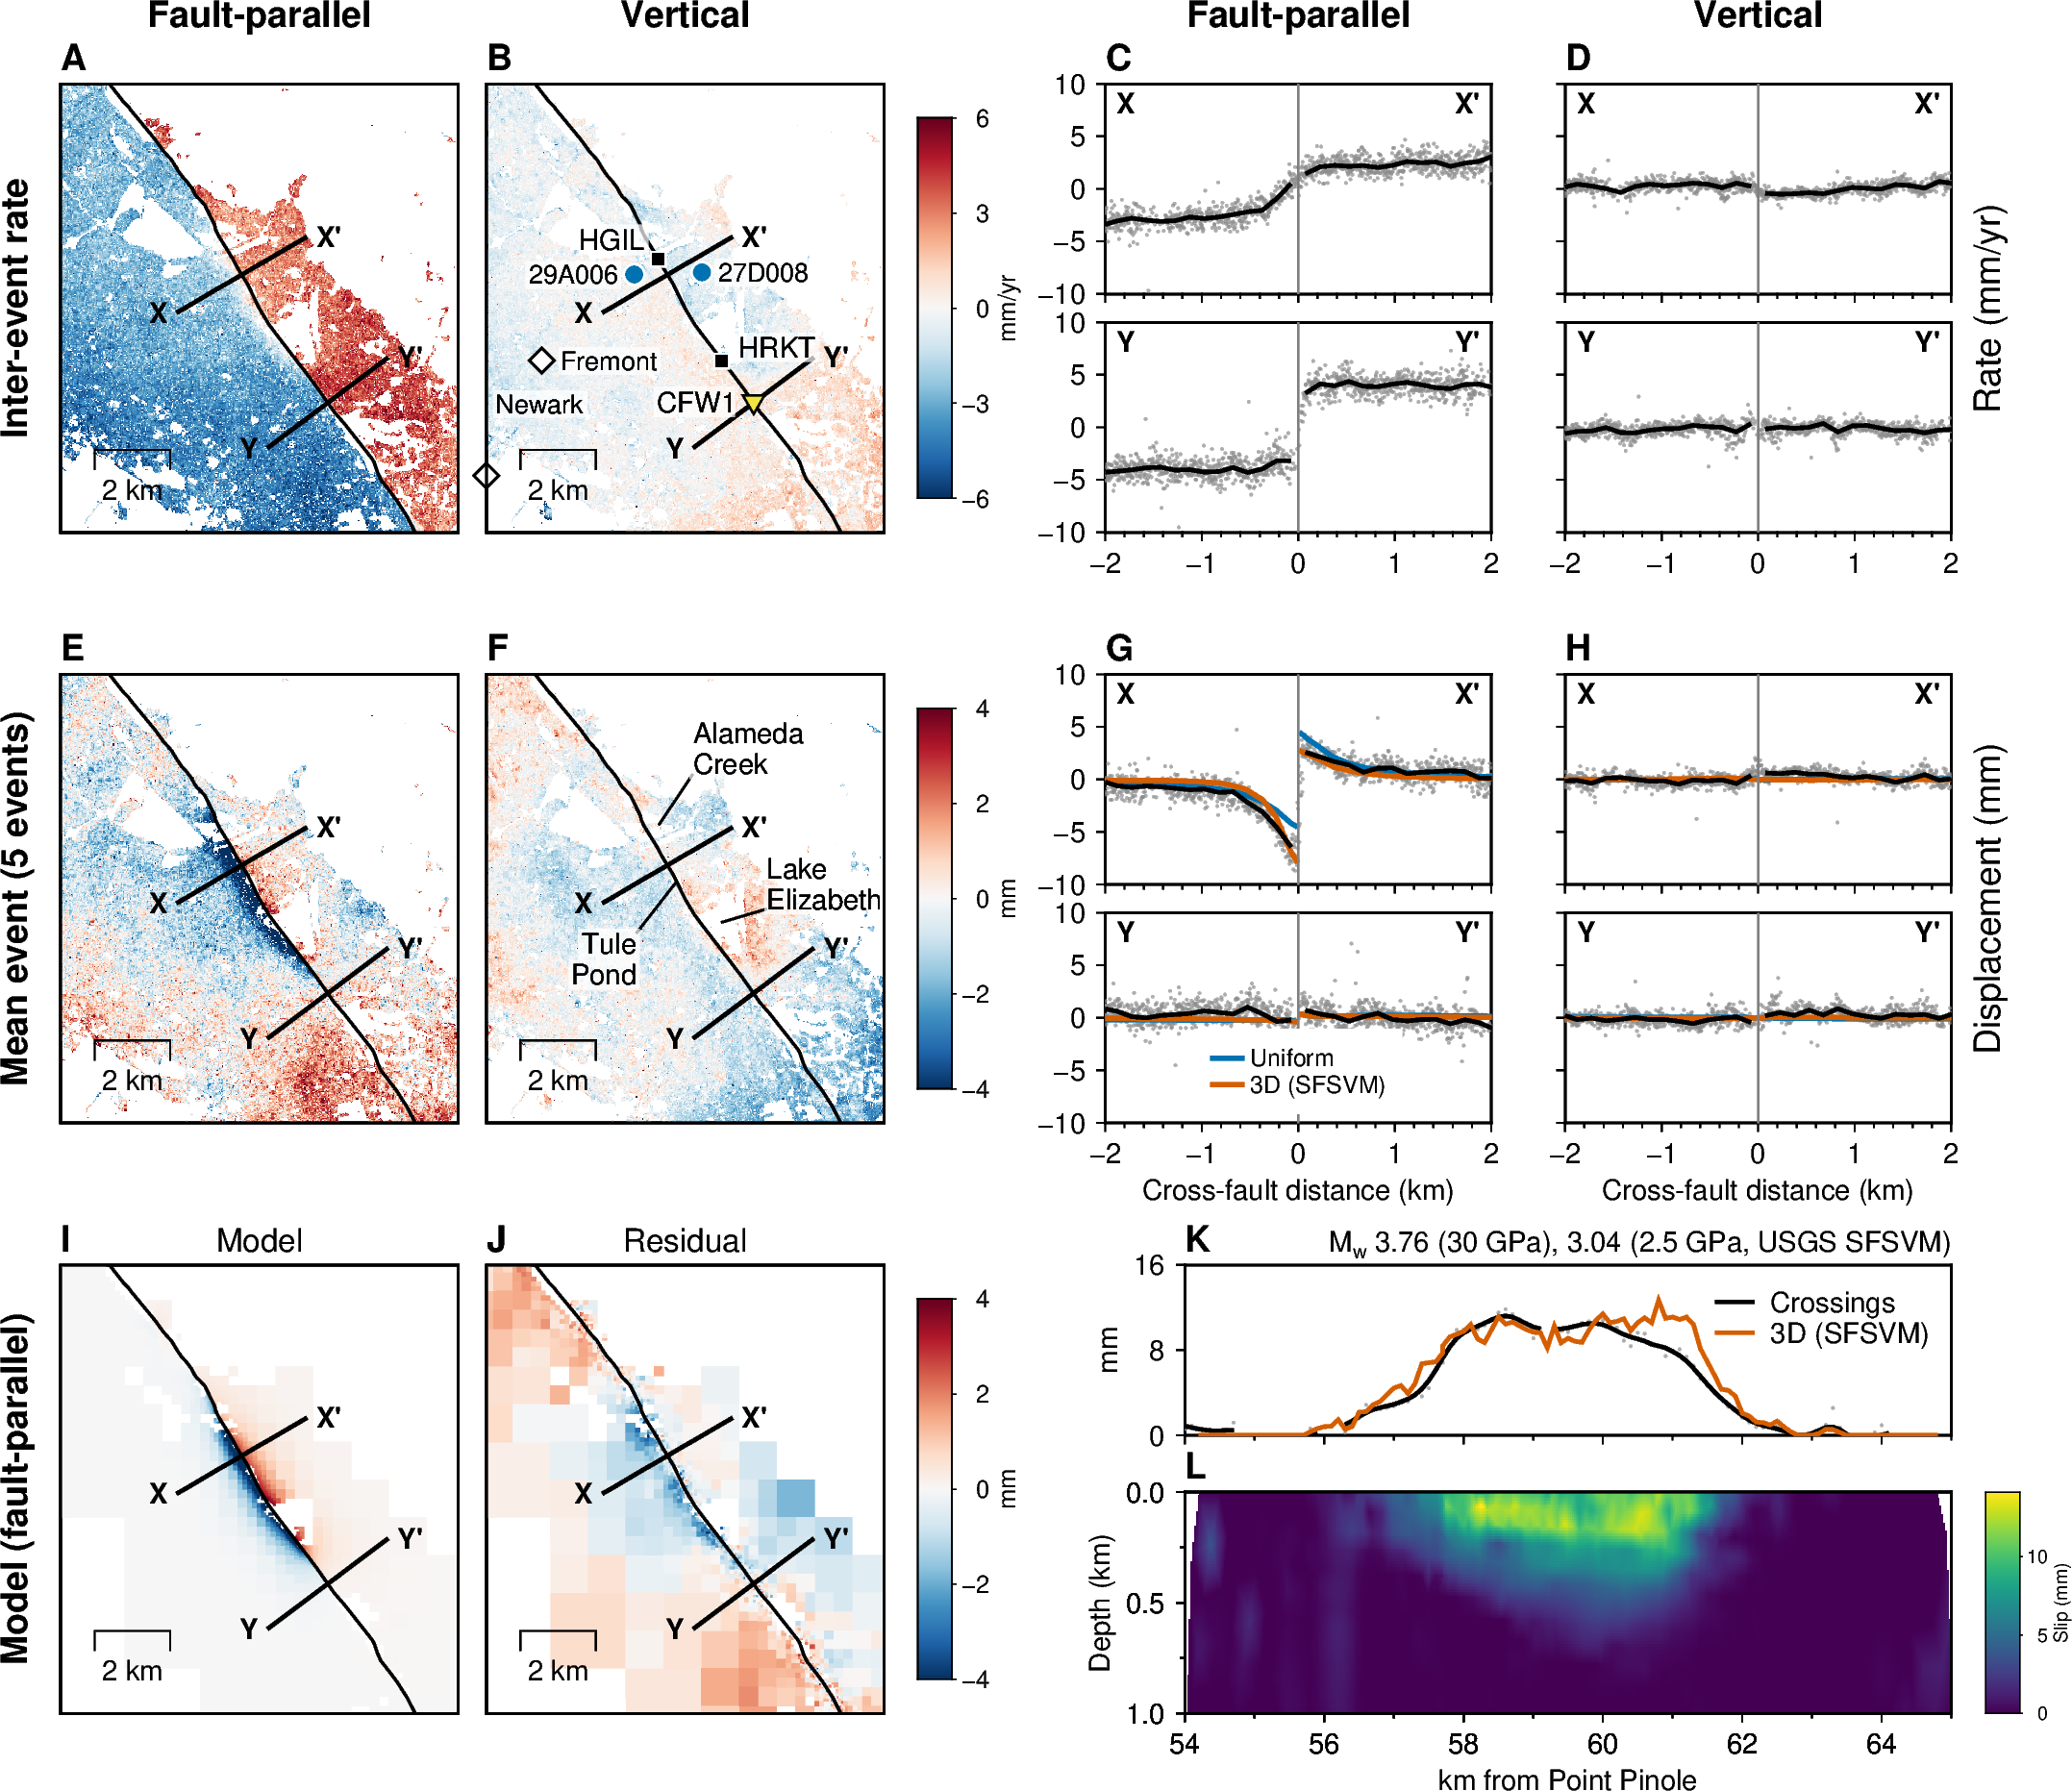

In [5]:
fpup_rate = {"fault-parallel": fp_rate, "vertical": up_rate}
fpup_evt = {"fault-parallel": fp_evt, "vertical": up_evt}
fpup_profiles = {"fault-parallel": profiles, "vertical": up_profiles}
for c in fpup_profiles:
    for n_, p in fpup_profiles[c].items():
        print(f"[{c}] {n_}-{n_}': per block W {p['blocks']['W']['amp']:+.2f} +/- {p['blocks']['W']['se']:.2f}, "
              f"E {p['blocks']['E']['amp']:+.2f} +/- {p['blocks']['E']['se']:.2f} mm")
# Model lines on G/H: the model product's own profiles, and (TULEPOND_FIG2_COMPARE) a second product's profiles
# drawn underneath, e.g. the homogeneous PyLith model with the same inversion, so G shows the symmetric
# homogeneous prediction (blue) against the asymmetric aligned-SFCVM one (vermillion). Panels I-L stay the model's.
def profile_lines(path):
    zz = np.load(path)
    return {(col, n_): (zz[f"prof_{n_}_{key}_d"], zz[f"prof_{n_}_{key}_mm"])
            for col, key in (("fault-parallel", "fp"), ("vertical", "up")) for n_ in names}


model_lines = []
if os.path.exists(model_row_file):
    z_model = np.load(model_row_file)
    model_is_hetero = "aligned" in str(z_model["sfcvm_version"]) if "sfcvm_version" in z_model.files else False
    model_col = hetero_col if model_is_hetero else homog_col
    default_compare = pylith_compare if (model_row_file == pylith_model and os.path.exists(pylith_compare)) else ""
    compare_file = os.environ.get("TULEPOND_FIG2_COMPARE", default_compare)
    if compare_file:
        assert os.path.exists(compare_file), f"comparison product missing: {compare_file}"
        model_lines.append((profile_lines(compare_file), homog_col, "Uniform"))
    model_lines.append((profile_lines(model_row_file), model_col, "3D (SFSVM)" if model_is_hetero else "Model"))   # no commas: GMT legend labels stop at one
f_fig2_fp = os.path.join(fig_dir, f"fig2_fault_parallel_vertical_coh{coh_maps:g}_{n_mean}ev{model_tag}")
draw_fig2(fpup_evt, fpup_profiles, f"Mean event ({n_mean} events)", f_fig2_fp,
          rate_maps_in=fpup_rate, cols=list(fpup_rate), ylabs=("Rate (mm/yr)", "Displacement (mm)"),
          lims={"rate": 10.0, "event": 10.0}, model_lines=model_lines)